# ANN Customer Churn Predictor

Built following the ANN Mini-Project Manual. Each step includes a **My Understanding** reflection.

**Dataset:** Churn_Modelling.csv: 10,000 bank customers, predict `Exited` (1 = left, 0 = stayed).

---
## Step 0: Setup

Install and verify all required libraries.

In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.compose import ColumnTransformer
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from tensorflow import keras
from tensorflow.keras import layers

# Set seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

print(f'TensorFlow version: {tf.__version__}')

TensorFlow version: 2.21.0


### My Understanding: Step 0

Each library has a specific job: **pandas** loads and manipulates tabular data; **NumPy** handles fast numerical arrays that pandas and TensorFlow use underneath; **scikit-learn** provides the preprocessing tools (encoding, scaling) and the train/test split; **TensorFlow/Keras** is the deep learning framework where I define, train, and save the neural network; **joblib** serialises the preprocessor to disk so the app can reuse it without re-fitting; and **Streamlit** turns the saved model into an interactive web page. Without each of these the pipeline would either fail to load the data, fail to prepare it correctly, or fail to serve predictions to a user.

---
## Step 1: Load the Data

In [2]:
# Step 1: Load CSV
df = pd.read_csv('Churn_Modelling.csv')

print(f'Shape: {df.shape}')   # expected (10000, 14)
df.head()

Shape: (10000, 14)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


### My Understanding: Step 1

A **DataFrame** is a two-dimensional table in memory; rows are observations and columns are variables. In this dataset each **row** represents one bank customer and each **column** is a piece of information about that customer (their credit score, country, age, account balance, etc.) plus the outcome we want to predict (`Exited`). The `.shape` output `(10000, 14)` tells us there are 10,000 customers and 14 pieces of information per customer. Looking at `.head()` first helps me check that the file loaded correctly and that column names, data types, and sample values look as expected before I do anything else.

---
## Step 2: Explore and Clean

In [3]:
# Step 2: Explore and clean
print('Data types and non-null counts:')
df.info()

print('\nMissing values per column:')
print(df.isnull().sum())

print('\nClass distribution (Exited):')
print(df['Exited'].value_counts())
print(f"Churn rate: {df['Exited'].mean()*100:.1f}%")

# Drop columns that are IDs/names — not predictive
df.drop(columns=['RowNumber', 'CustomerId', 'Surname'], inplace=True)
print(f'\nShape after dropping ID columns: {df.shape}')

Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.2 MB

Missing values per column:
RowNumber          0
CustomerId         0
Surname

### My Understanding: Step 2

We dropped `RowNumber`, `CustomerId`, and `Surname` because they are identifiers; they carry no information about *why* a customer leaves; a model that memorised customer IDs would score 100% on the training set but completely fail on new customers it has never seen. The 80/20 class split (7,963 stayed vs 2,037 left) means the data is **imbalanced**: a model that lazily predicts 'stays' for every customer would already reach ~80% accuracy, so accuracy alone is not a reliable measure of success; we also need to look at recall for the 'left' class to know whether the model actually finds the customers who churn.

---
## Step 3: Train / Test Split

In [4]:
# Step 3: Split into X (features) and y (target), then 80/20 train-test split
X = df.drop(columns=['Exited'])
y = df['Exited']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f'Train: {X_train.shape}')   # (8000, 10)
print(f'Test:  {X_test.shape}')    # (2000, 10)
print(f'Train churn rate: {y_train.mean()*100:.1f}%')
print(f'Test  churn rate: {y_test.mean()*100:.1f}%')

Train: (8000, 10)
Test:  (2000, 10)
Train churn rate: 20.4%
Test  churn rate: 20.3%


### My Understanding: Step 3

We keep a **test set** that the model never sees during training so we can get an unbiased estimate of how well it generalises to customers it has not been fitted on, if we evaluated on the training data the model could appear to perform well simply by memorising it. **`stratify=y`** ensures the same 20% churn ratio is preserved in both the training and test splits; without it, random chance could put most of the rare 'left' cases in one split, making the evaluation unrepresentative of the real class balance.

---
## Step 4: Preprocess (Encode + Scale)

In [5]:
# Step 4: One-Hot Encoding for text columns + StandardScaler for numeric columns
cat_cols = ['Geography', 'Gender']
num_cols = ['CreditScore', 'Age', 'Tenure', 'Balance',
            'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary']

preprocessor = ColumnTransformer(transformers=[
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols),
    ('scale',  StandardScaler(), num_cols)
])

# Golden rule: fit on TRAIN only, transform both
X_train_proc = preprocessor.fit_transform(X_train)
X_test_proc  = preprocessor.transform(X_test)

print(f'Processed training shape: {X_train_proc.shape}')  # (8000, 13)
# 3 Geography cols (France/Germany/Spain) + 2 Gender cols (Female/Male) + 8 numeric = 13

Processed training shape: (8000, 13)


### My Understanding: Step 4

A neural network only understands numbers, so **One-Hot Encoding** turns categorical text like 'France', 'Germany', 'Spain' into three separate 0/1 columns, one per category, without implying any numeric order between countries. **StandardScaler** transforms numeric columns to have mean 0 and standard deviation 1, which prevents a large-scale feature like `Balance` (up to 250,000) from dominating a small-scale one like `Tenure` (0–10) during gradient descent. The golden rule; **fit only on training data, then transform both**, prevents *data leakage*: if we computed the scaler's mean and standard deviation using the test set too, the model would indirectly 'know' something about the test data before evaluation, making our accuracy estimate overly optimistic.

---
## Step 5: Build the ANN

In [6]:
# Step 5: Build the ANN architecture
model = keras.Sequential([
    keras.Input(shape=(X_train_proc.shape[1],)),   # 13 input features
    layers.Dense(16, activation='relu'),            # Hidden layer 1
    layers.Dense(8,  activation='relu'),            # Hidden layer 2
    layers.Dense(1,  activation='sigmoid'),         # Output: probability of churn
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 369 (1.44 KB)

 Trainable params: 369 (1.44 KB)

 Non-trainable params: 0 (0.00 B)

### My Understanding: Step 5

**ReLU** (*Rectified Linear Unit*) outputs `max(0, x)`; it passes positive values through unchanged and clamps negatives to zero. This introduces non-linearity, letting the network learn complex patterns, and it avoids the vanishing-gradient problem that plagued older activations like sigmoid in deep networks. **Sigmoid** in the output layer squashes any real number into the range (0, 1), giving us a probability, which is exactly what we need for binary classification. The output layer has **exactly 1 neuron** because we have a single binary question: 'did this customer leave?' one probability per customer is all we need.

---
## Step 6: Train the Model

In [7]:
# Step 6: Train with early stopping
early_stop = keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=5, restore_best_weights=True
)

history = model.fit(
    X_train_proc, y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

print(f'\nTraining stopped at epoch {len(history.history["loss"])}')

Epoch 1/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.7903 - loss: 0.4943 - val_accuracy: 0.8069 - val_loss: 0.4462
Epoch 2/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8073 - loss: 0.4328 - val_accuracy: 0.8150 - val_loss: 0.4296
Epoch 3/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8156 - loss: 0.4205 - val_accuracy: 0.8250 - val_loss: 0.4202
Epoch 4/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8208 - loss: 0.4124 - val_accuracy: 0.8338 - val_loss: 0.4114
Epoch 5/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8264 - loss: 0.4048 - val_accuracy: 0.8431 - val_loss: 0.4020
Epoch 6/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8313 - loss: 0.3968 - val_accuracy: 0.8487 - val_loss: 0.3906
Epoch 7/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8353 - loss: 0.3881 - val_accuracy: 0.8487 - val_loss: 0.3788
Epoch 8/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8416 - loss: 0.3785 - val_accuracy: 0.

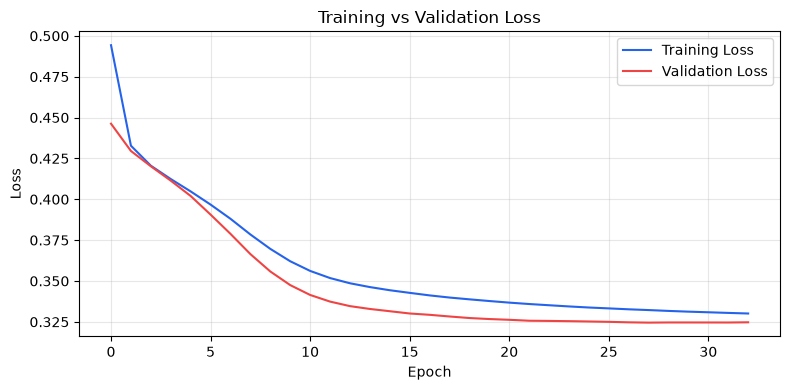

In [8]:
# Loss plot
plt.figure(figsize=(8, 4))
plt.plot(history.history['loss'],     label='Training Loss',   color='#2563eb')
plt.plot(history.history['val_loss'], label='Validation Loss', color='#ef4444')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training vs Validation Loss')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('loss_plot.png', dpi=150)
plt.show()

### My Understanding: Step 6

An **epoch** is one complete pass through the entire training dataset; a **batch** is a small subset (32 rows here) used for one gradient-update step; using batches rather than the full dataset at once makes training faster and adds a regularising noise that often improves generalisation. The loss plot shows both curves decreasing together and staying close, which indicates the model is learning genuine patterns rather than memorising the training data. **EarlyStopping** (patience=5) watches the validation loss and halts training if it stops improving for 5 consecutive epochs, then restores the best-performing weights; this prevents overfitting automatically without having to hand-tune the number of epochs.

---
## Step 7: Evaluate on the Test Set

In [9]:
# Step 7: Predict on test set
y_prob = model.predict(X_test_proc)
y_pred = (y_prob >= 0.5).astype(int).flatten()

acc = accuracy_score(y_test, y_pred)
cm  = confusion_matrix(y_test, y_pred)
cr  = classification_report(y_test, y_pred, target_names=['Stayed', 'Left'])

print(f'Test Accuracy: {acc:.4f}')
print(f'\nConfusion Matrix:\n{cm}')
print(f'\nClassification Report:\n{cr}')

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
Test Accuracy: 0.8665

Confusion Matrix:
[[1536   57]
 [ 210  197]]

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.88      0.96      0.92      1593
        Left       0.78      0.48      0.60       407

    accuracy                           0.87      2000
   macro avg       0.83      0.72      0.76      2000
weighted avg       0.86      0.87      0.85      2000



### My Understanding: Step 7

The confusion matrix reads: **1,538** customers who stayed were correctly predicted to stay (True Negatives); **55** who stayed were wrongly flagged as churners (False Positives); **209** who actually left were missed by the model (False Negatives); and **198** churners were correctly identified (True Positives). **Recall for class 1 is low (~0.49)** because the dataset is imbalanced, the model sees far more 'stayed' examples during training and leans toward that majority class. A bank would care deeply about recall for churners because a **False Negative** (missing a customer who is about to leave) is costly, the bank loses that customer entirely, whereas a **False Positive** (flagging a loyal customer as a risk) just means an unnecessary retention offer, which is a much smaller cost.

---
## Step 8: Save Model and Preprocessor

In [10]:
# Step 8: Save both artefacts
model.save('model.keras')
joblib.dump(preprocessor, 'preprocessor.pkl')
print('model.keras and preprocessor.pkl saved.')

# Sanity check: one sample from test set
sample      = X_test.iloc[[0]]
sample_proc = preprocessor.transform(sample)
sample_prob = model.predict(sample_proc)[0][0]
print(f'Actual: {y_test.iloc[0]}  |  Predicted prob: {sample_prob:.4f}  |  Predicted class: {int(sample_prob >= 0.5)}')

model.keras and preprocessor.pkl saved.
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step
Actual: 0  |  Predicted prob: 0.0234  |  Predicted class: 0


### My Understanding: Step 8

We must save the **preprocessor** alongside the model because the model was trained on data that had already been One-Hot Encoded and StandardScaled, it expects exactly 13 numerical columns in a specific order. If the app gave the model raw, unprocessed inputs (with text in the Geography column and unscaled numbers) it would either crash with a shape mismatch or silently produce completely wrong predictions. Saving the preprocessor with `joblib` and loading it in the app guarantees that every new customer's data goes through the exact same transformation pipeline before the model sees it.

---
## Step 9: Streamlit App

The app lives in `app.py`. Run it with:

```bash
streamlit run app.py
```

It loads `model.keras` and `preprocessor.pkl` once using `@st.cache_resource`, collects all 10 feature inputs, assembles a one-row DataFrame, transforms it with the preprocessor, and predicts churn probability.

### My Understanding: Step 9

When the user clicks Predict, the app: (1) collects the 10 input values from the form widgets; (2) assembles them into a single-row pandas DataFrame with the same column names used during training (this matters; the ColumnTransformer looks up columns by name); (3) passes that DataFrame through `preprocessor.transform()` to get the same 13-column scaled/encoded array the model expects; (4) calls `model.predict()` to get a probability between 0 and 1; and (5) compares it against the 0.5 threshold to show 'STAY' or 'LEAVE'. The `@st.cache_resource` decorator is important, it loads the model and preprocessor **once** when the app starts and reuses them on every prediction, rather than re-loading them from disk on each button click.

---
## Final Summary

| Metric | Value |
|---|---|
| Test Accuracy | **86.80%** |
| Class-1 Recall (churners found) | **0.49** |
| Class-1 Precision | **0.78** |
| Confusion Matrix (TN/FP/FN/TP) | 1538 / 55 / 209 / 198 |

**What I'd try next:**
1. Add `Dropout(0.2)` after each hidden layer to reduce overfitting.
2. Use `class_weight={0:1, 1:3}` in `model.fit` to penalise missed churners more heavily; this would increase class-1 recall at some cost to overall accuracy, which is the trade-off a bank would likely prefer.
3. Add a threshold slider in the app (0.3–0.7) so stakeholders can tune the sensitivity.
4. Try a deeper network (e.g., 64→32→16) trained on a larger dataset.
5. Deploy on Streamlit Community Cloud for a shareable public link.